# XAI case study: what the G1 obstacle policy looks at

A PPO policy steers a Unitree G1 humanoid (MuJoCo) around boxes. A frozen walking policy moves the joints; on top of it a CNN reads a 64×64 RGB camera image plus a 6-number state and outputs a correction to the velocity command (vx, vy, yaw rate).

**Question.** Does the CNN avoid the boxes because it sees the obstacle, or because of a shortcut (colour, floor, shadows)?
**Stakeholder.** Whoever decides whether this policy can move from simulation to the real robot.

This notebook loads the model and the evaluation data, shows the evaluation metrics, computes and displays the explanations, the sanity checks and the actionable before/after experiment. Every table and figure is produced by the scripts listed in the README; the notebook reads their outputs from `results/` and calls `src/` for live examples (these need the rollouts in `data/`).

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

REPO = Path.cwd().resolve()
if not (REPO / "src").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO))
RESULTS = REPO / "results"
FIGURES = RESULTS / "figures"
DATA = REPO / "data" / "raw" if (REPO / "data" / "raw").exists() else REPO / "data" / "rollouts"
HAVE_DATA = DATA.exists() and any(DATA.glob("*/b*_s*.npz"))
pd.set_option("display.precision", 3)
print("repository folder:", REPO.name)
print("rollout data available:", HAVE_DATA, f"({DATA.relative_to(REPO)})" if HAVE_DATA else "- live cells will be skipped")

repository folder: scaffold
rollout data available: False - live cells will be skipped


## 1. Model

In [2]:
from src.load_policy import SteeringNet, load_ppo, gradcam_layers, N_PARAMETERS

model = load_ppo()
net = SteeringNet(model.policy).eval()
print(model.policy)
print("parameters:", sum(p.numel() for p in model.policy.parameters()), "(expected", N_PARAMETERS, ")")
print("Grad-CAM layers:", {k: type(v).__name__ for k, v in gradcam_layers(model.policy).items()})

MultiInputActorCriticPolicy(
  (features_extractor): CombinedExtractor(
    (extractors): ModuleDict(
      (image): NatureCNN(
        (cnn): Sequential(
          (0): Conv2d(3, 32, kernel_size=(8, 8), stride=(4, 4))
          (1): ReLU()
          (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
          (3): ReLU()
          (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1))
          (5): ReLU()
          (6): Flatten(start_dim=1, end_dim=-1)
        )
        (linear): Sequential(
          (0): Linear(in_features=1024, out_features=256, bias=True)
          (1): ReLU()
        )
      )
      (state): Flatten(start_dim=1, end_dim=-1)
    )
  )
  (pi_features_extractor): CombinedExtractor(
    (extractors): ModuleDict(
      (image): NatureCNN(
        (cnn): Sequential(
          (0): Conv2d(3, 32, kernel_size=(8, 8), stride=(4, 4))
          (1): ReLU()
          (2): Conv2d(32, 64, kernel_size=(4, 4), stride=(2, 2))
          (3): ReLU()
          (4): Conv2d(64, 64

The explained outputs are the raw action mean before the clip and the EMA (μ vx, μ vy) and the critic's value V, which shares the CNN. The yaw output is only a control.

## 2. Data: the rollout dataset

In [3]:
episodes = pd.read_csv(RESULTS / "episodes.csv")
summary = episodes.groupby("set").agg(episodes=("seed", "size"), frames=("frames", "sum"),
                                       boxes=("boxes", lambda b: sorted(set(b))))
summary

,episodes,frames,boxes
set,,,
baseline_black,51,8069,"[10, 20, 30]"
baseline_mask_random,51,9894,"[10, 20, 30]"
baseline_mask_top,51,8836,"[10, 20, 30]"
baseline_noise,51,4857,"[10, 20, 30]"
baseline_walker,51,4783,"[10, 20, 30]"
int_hue_box_colour,300,58266,"[10, 20, 30]"
int_hue_test_id,51,10023,"[10, 20, 30]"
int_norm_floor_tint,300,58467,"[10, 20, 30]"
int_norm_test_id,51,10147,"[10, 20, 30]"


Each episode is one `.npz` file: per step the state (6), raw mean (3), V, applied action, command, distance to the nearest box, `qpos`; per episode the box centres and sizes and the outcome. Twenty episodes per set also store the 64×64 image the policy saw and a per-pixel box segmentation rendered from the same simulator state. Seeds 1000+ are the validation seeds already used during training evaluation; seeds 2000+ were never used (Test-ID). Out-of-distribution sets reuse the Test-ID seeds with a different box colour, floor tint or lighting. See `data/README.md` for the full description.

In [4]:
if HAVE_DATA:
    from src.attribution import load_frames
    frames = load_frames(DATA, sets=["test_id"])
    idx = np.linspace(0, len(frames) - 1, 6).astype(int)
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.2))
    for k, i in enumerate(idx):
        axes[0, k].imshow(frames.image[i]); axes[0, k].set_title(f"μvx {frames.mean[i, 0]:.2f}", fontsize=8)
        axes[1, k].imshow(frames.mask[i] >= 0, cmap="gray")
        for a in axes[:, k]: a.axis("off")
    axes[0, 0].set_ylabel("image"); axes[1, 0].set_ylabel("box mask")
    plt.tight_layout(); plt.show()
else:
    print("skipped: no rollout data")

skipped: no rollout data


## 3. Evaluation of the model

In [5]:
by_set = pd.read_csv(RESULTS / "metrics_by_set.csv")
cols = ["set", "n", "success", "success_lo", "success_hi", "box_hit", "fall", "progress", "min_clearance", "saturated_vy"]
by_set[cols]

,set,n,success,success_lo,success_hi,box_hit,fall,progress,min_clearance,saturated_vy
0,baseline_black,51,0.000,0.000,0.070,0.255,0.000,0.036,1.827,0.000
1,baseline_mask_random,51,0.941,0.841,0.980,0.059,0.000,0.937,0.764,NaN
2,baseline_mask_top,51,0.745,0.611,0.845,0.255,0.000,0.858,0.666,NaN
3,baseline_noise,51,0.216,0.125,0.346,0.784,0.000,0.443,0.468,0.007
4,baseline_walker,51,0.196,0.110,0.325,0.804,0.000,0.413,0.485,NaN
5,int_hue_box_colour,300,0.933,0.899,0.956,0.053,0.003,0.950,0.687,0.465
6,int_hue_test_id,51,0.980,0.897,0.997,0.020,0.000,0.944,0.777,0.474
7,int_norm_floor_tint,300,0.923,0.888,0.948,0.050,0.007,0.913,0.709,0.382
8,int_norm_test_id,51,0.980,0.897,0.997,0.020,0.000,0.927,0.769,0.381
9,test_id,300,0.937,0.903,0.959,0.047,0.007,0.950,0.714,0.462


In [6]:
pd.read_csv(RESULTS / "metrics_by_density.csv")[["set", "boxes", "n", "success", "success_lo", "success_hi", "box_hit", "progress"]]

,set,boxes,n,success,success_lo,success_hi,box_hit,progress
0,baseline_black,10,17,0.000,0.000,0.184,0.059,0.030
1,baseline_black,20,17,0.000,0.000,0.184,0.235,0.036
2,baseline_black,30,17,0.000,0.000,0.184,0.471,0.041
3,baseline_mask_random,10,17,1.000,0.816,1.000,0.000,1.047
4,baseline_mask_random,20,17,0.882,0.657,0.967,0.118,0.938
5,baseline_mask_random,30,17,0.941,0.730,0.990,0.059,0.827
6,baseline_mask_top,10,17,0.824,0.590,0.938,0.176,0.981
7,baseline_mask_top,20,17,0.706,0.469,0.867,0.294,0.871
8,baseline_mask_top,30,17,0.706,0.469,0.867,0.294,0.723
9,baseline_noise,10,17,0.412,0.216,0.640,0.588,0.577


In [7]:
pd.read_csv(RESULTS / "command_deviation.csv")

,quantity,mean,lo,hi,n
0,speed_ratio,1.063e+00,1.006,1.124e+00,50
1,progress,1.116e+00,1.056,1.181e+00,50
2,end_y,2.696e-01,0.224,3.153e-01,50
3,correction_vx,2.245e-01,0.186,2.630e-01,50
4,correction_vy,4.932e-01,0.493,4.933e-01,50
5,correction_yaw,-3.666e-04,-0.002,9.180e-04,50


Rates are pooled over 10, 20 and 30 boxes with 95 % Wilson intervals; continuous quantities have bootstrap intervals. `command_deviation` is measured with no boxes (Test-ID-0): how far the policy moves the robot away from the user's command when there is nothing to avoid.

**Interpretation:** _(to be written)_

## 4. Global explanations

### 4.1 Group permutation importance

scalar,V,vx,vy,yaw
group,,,,
image,0.570,0.846,1.049,1.206
speed,0.573,0.021,0.015,0.020
heading,0.206,0.014,0.179,0.753
prev_action,0.024,0.149,0.047,0.206


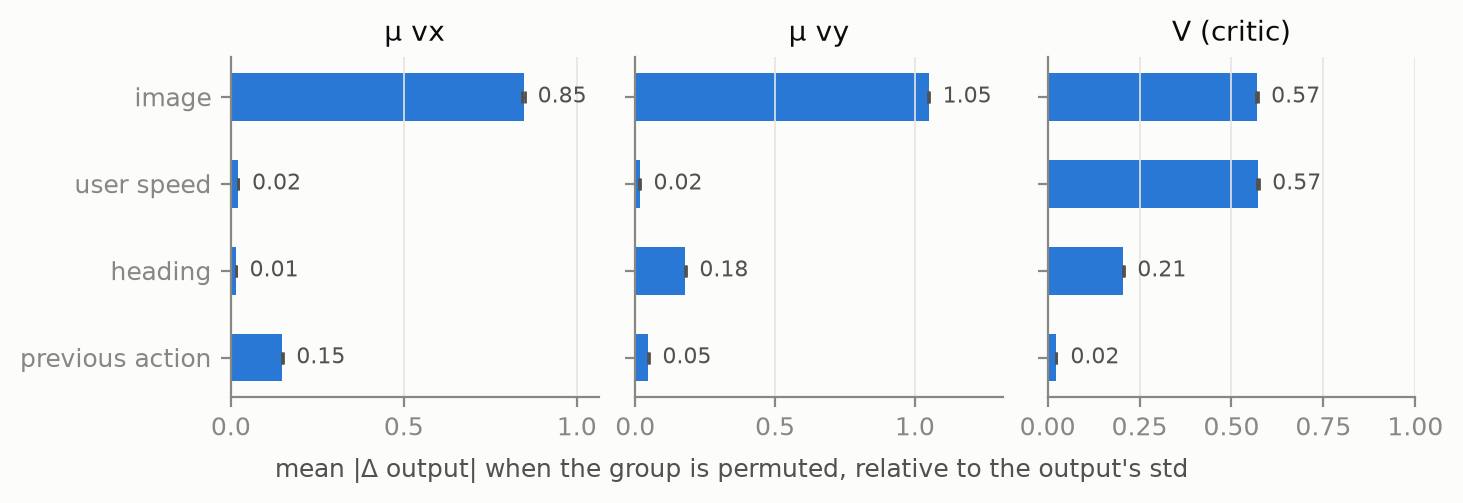

In [8]:
pfi = pd.read_csv(RESULTS / "group_pfi.csv")
display(pfi.pivot(index="group", columns="scalar", values="relative").loc[["image", "speed", "heading", "prev_action"]])
display(Image(FIGURES / "group_pfi.png"))

Each input group (image, user speed, heading, previous action) is replaced by the same group from a frame of another episode; the bars are the mean |change| of the output relative to its standard deviation, with 95 % intervals over 10 permutations.

**Interpretation:** _(to be written)_

### 4.2 Integrated Gradients aggregated by input group, against distance to the nearest box

50%    90%
baseline scalar              
black    V       0.005  0.013
         vx      0.006  0.020
         vy      0.008  0.021
blur     V       0.001  0.010
         vx      0.002  0.010
         vy      0.003  0.018

bin                  0      1      2      3      4      5      6      7
baseline scalar                                                        
black    V       0.970  0.973  0.970  0.975  0.981  0.980  0.978  0.977
         vx      0.994  0.993  0.994  0.995  0.996  0.996  0.996  0.996
         vy      0.992  0.991  0.992  0.994  0.995  0.997  0.997  0.996
blur     V       0.795  0.808  0.771  0.777  0.821  0.797  0.770  0.737
         vx      0.971  0.966  0.966  0.967  0.970  0.970  0.971  0.969
         vy      0.946  0.949  0.950  0.961  0.969  0.976  0.976  0.973

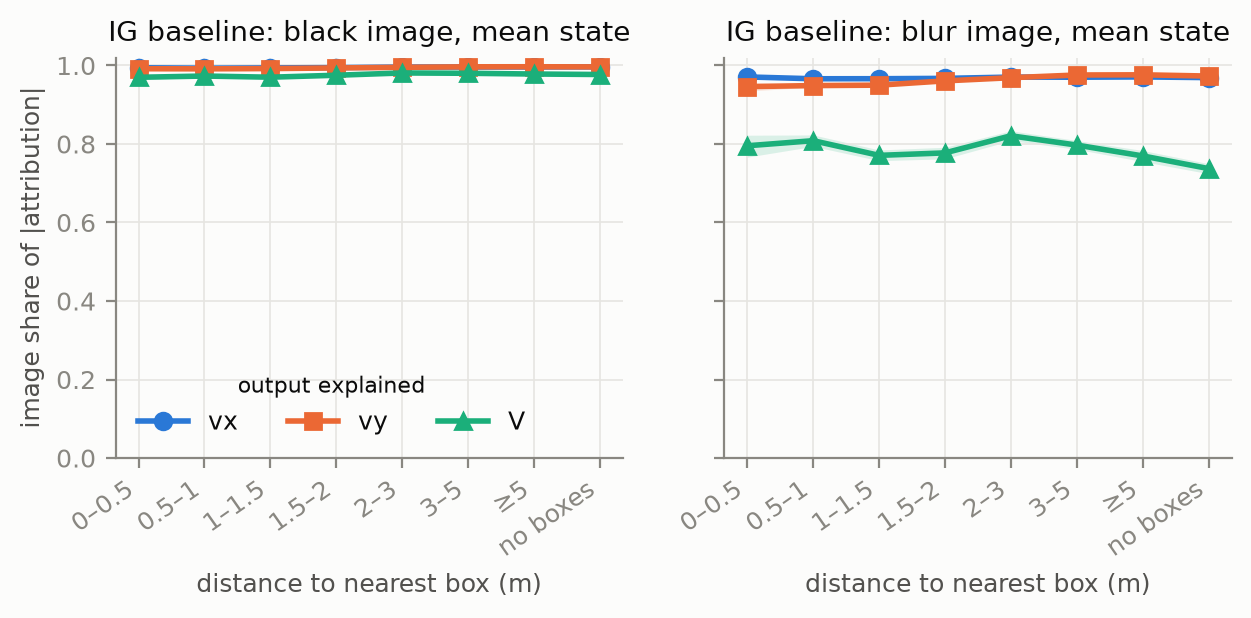

In [9]:
ig = pd.read_csv(RESULTS / "ig_groups.csv")
display(ig.groupby(["baseline", "scalar"])["completeness_error"].describe(percentiles=[0.5, 0.9])[["50%", "90%"]])
display(ig.groupby(["baseline", "scalar", "bin"])["image_share"].mean().unstack("bin").round(3))
display(Image(FIGURES / "ig_image_share.png"))

`completeness_error` is |sum of attributions − (f(x) − f(baseline))| relative to the gap (256 steps). The image share is the image's part of the absolute attribution; the state baseline is the mean logged state.

**Interpretation:** _(to be written)_

## 5. Local explanations

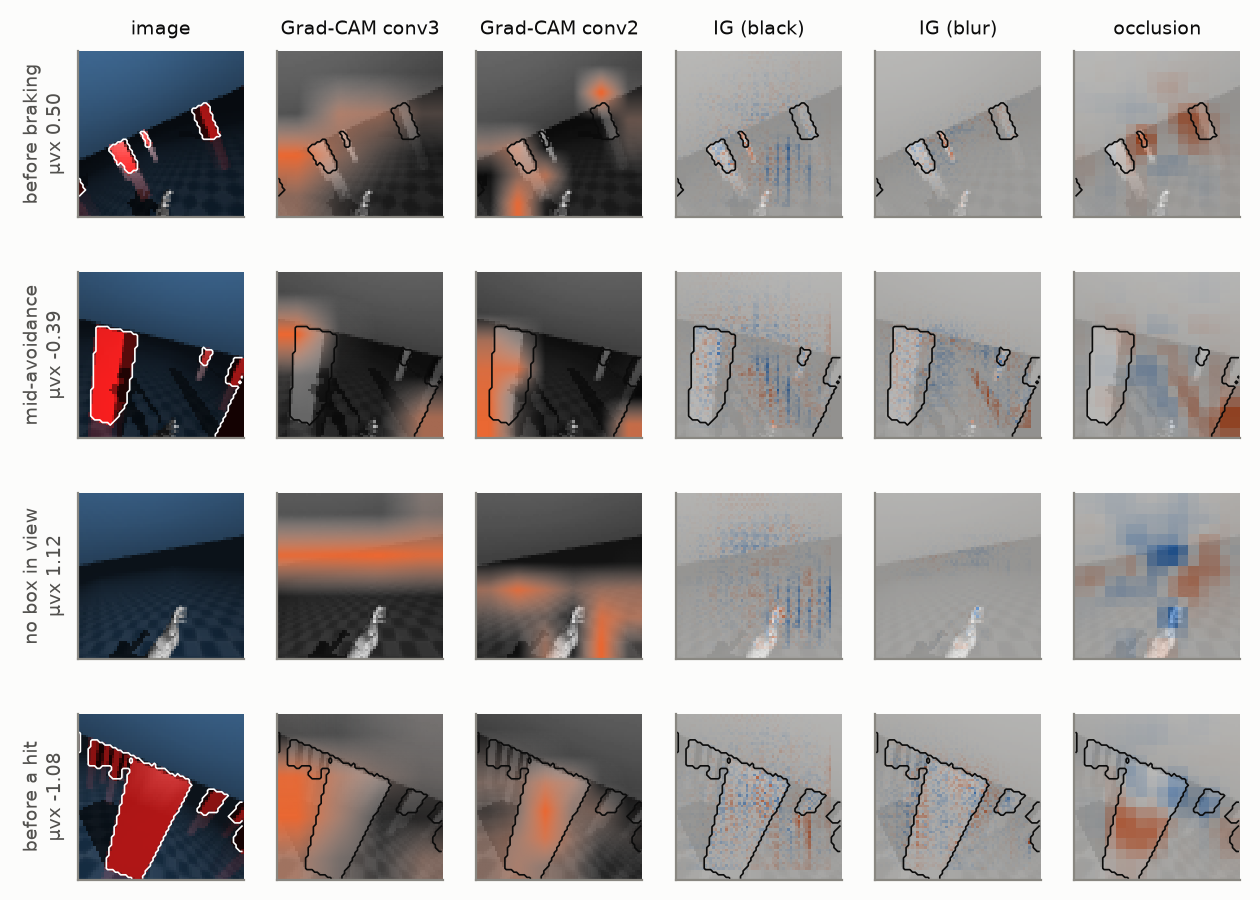

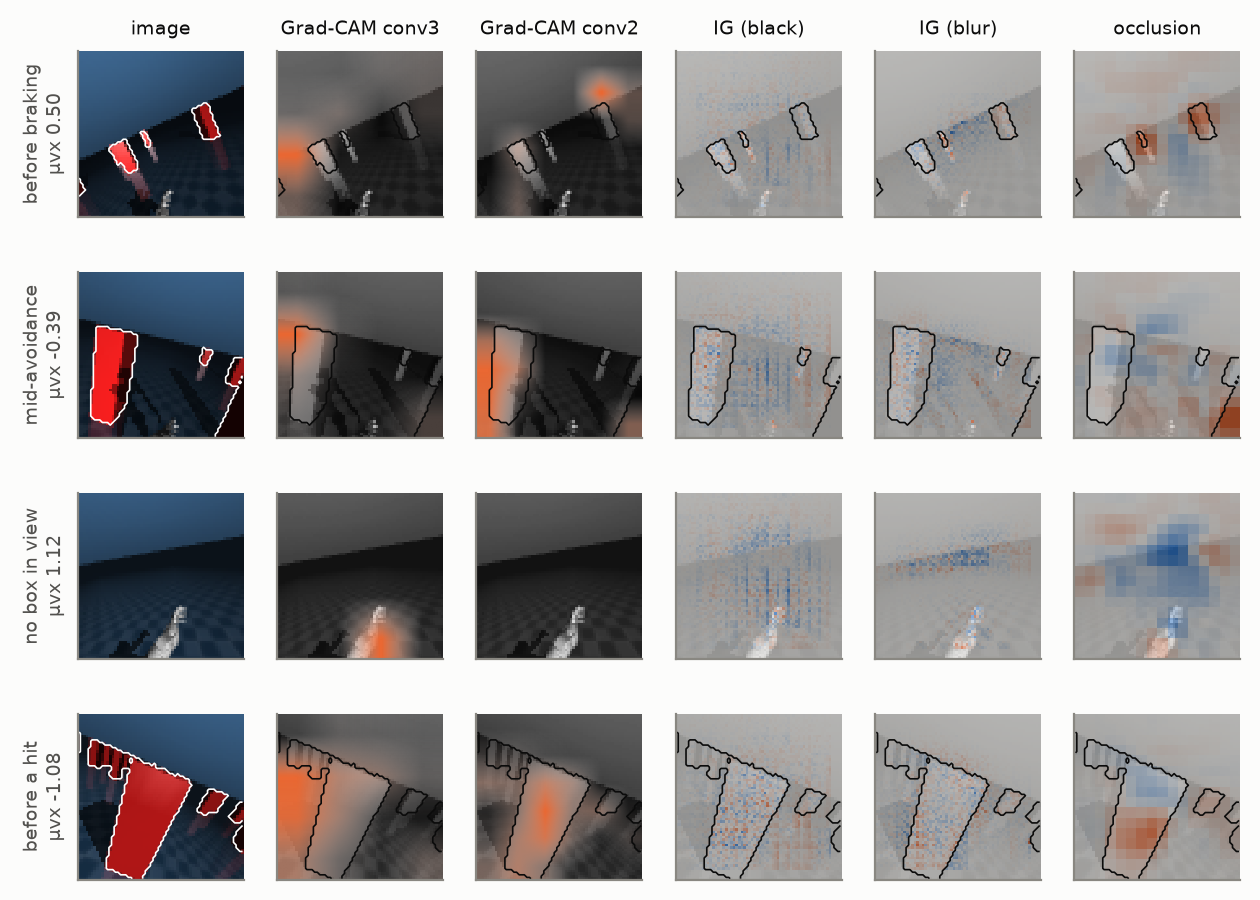

In [10]:
display(Image(FIGURES / "local_maps_vx.png"))
display(Image(FIGURES / "local_maps_vy.png"))

Frames chosen automatically from the logs: just before braking, mid-avoidance, no box in view, and the steps before a hit (when any image episode has one). Maps explain s = −μ vx (evidence for braking) and s = −μ vy (evidence for reducing the push to the left); positive evidence is orange. Box outlines come from the logged segmentation.

In [11]:
if HAVE_DATA:
    from src.attribution import local_maps
    from src.plotstyle import overlay
    i = int(np.argmax((frames.mask >= 0).reshape(len(frames), -1).sum(1)))
    fig, axes = plt.subplots(1, 4, figsize=(9, 2.6))
    axes[0].imshow(frames.image[i]); axes[0].axis("off"); axes[0].set_title("image", fontsize=8)
    for ax, m in zip(axes[1:], ["gradcam_conv2", "ig_blur", "occlusion"]):
        maps = local_maps(net, frames.image[i:i + 1], frames.state[i:i + 1], "vx", m, steps=64)
        overlay(ax, frames.image[i], maps[0], frames.mask[i], signed=not m.startswith("gradcam")); ax.set_title(m, fontsize=8)
    plt.tight_layout(); plt.show()
else:
    print("skipped: no rollout data")

skipped: no rollout data


### 5.1 Localisation: q_RRA against the box segmentation

In [12]:
q = pd.read_csv(RESULTS / "q_rra.csv")
q[q.frames == "all"].pivot_table(index=["scalar", "method"], columns="set", values="ratio").round(2)

set                   test_id  test_ood_box_colour  test_ood_floor_tint  \
scalar method                                                             
vx     gradcam_conv2     3.08                 3.13                 3.44   
       gradcam_conv3     3.47                 2.53                 3.26   
       ig_black          2.29                 2.38                 2.36   
       ig_blur           3.55                 2.69                 3.54   
       occlusion         3.20                 2.34                 2.67   
vy     gradcam_conv2     3.56                 1.44                 4.05   
       gradcam_conv3     3.13                 1.74                 3.42   
       ig_black          2.72                 2.91                 2.58   
       ig_blur           3.86                 2.89                 4.00   
       occlusion         3.71                 2.66                 3.21   

set                   test_ood_lighting  
scalar method                            
vx     gradcam_conv2               2.66  
       gradcam_conv3               3.16  
       ig_black                    2.60  
       ig_blur                     3.91  
       occlusion                   3.99  
vy     gradcam_conv2               3.27  
       gradcam_conv3               2.20  
       ig_black                    2.86  
       ig_blur                     4.36  
       occlusion                   3.80

q_RRA is the share of a map's top-|s| pixels that fall on boxes (s = box pixels); the table divides it by the expected value of a random map, |s|/d. A value of 1 is chance.

**Interpretation:** _(to be written)_

### 5.2 The same state under each look (re-rendered pairs)

,mu_vx,mu_vy,V,q_rra_vx_gradcam_conv2,q_rra_vx_occlusion,q_rra_vy_gradcam_conv2
variant,,,,,,
box_colour,0.520,0.337,-0.967,0.009,-0.058,-0.244
floor_tint,-0.586,-0.317,-16.057,-0.013,-0.025,-0.062
lighting,0.605,0.175,9.094,-0.044,0.068,-0.021


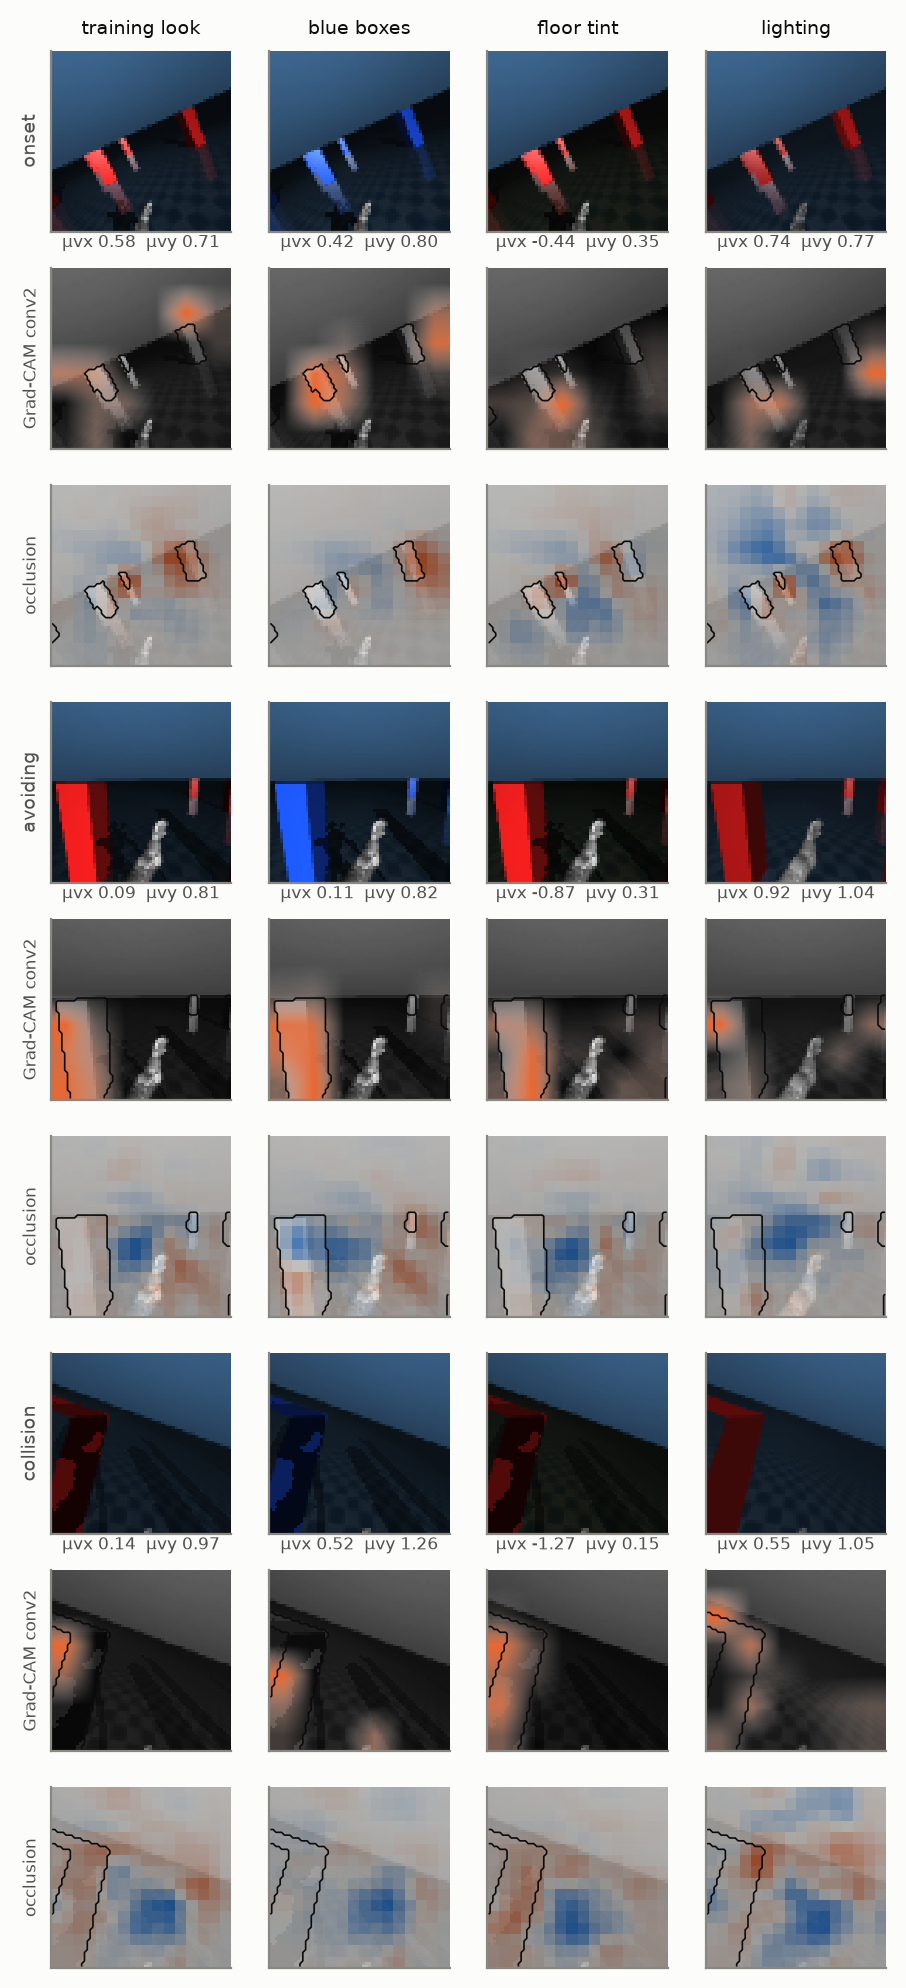

In [13]:
pairs = pd.read_csv(RESULTS / "pairs.csv")
base = pairs[pairs.variant == "id"].set_index("pair")
rows = []
for v in ["box_colour", "floor_tint", "lighting"]:
    d = pairs[pairs.variant == v].set_index("pair")
    rows.append({"variant": v, **{c: (d[c] - base[c]).mean() for c in ["mu_vx", "mu_vy", "V", "q_rra_vx_gradcam_conv2", "q_rra_vx_occlusion", "q_rra_vy_gradcam_conv2"]}})
display(pd.DataFrame(rows).set_index("variant").round(3))
display(Image(FIGURES / "pairs_vx.png"))

Logged Test-ID states re-rendered under the training look and each variant (both members re-rendered, outputs recomputed on the re-rendered images). The table is the mean change from the training look on the same states.

**Interpretation:** _(to be written)_

In [14]:
from IPython.display import Video
videos = sorted(FIGURES.glob("gradcam_*.mp4"))
prefix = "../" if Path.cwd().name == "notebooks" else ""
display(Video(url=f"{prefix}results/figures/{videos[0].name}", width=520) if videos else "no video found")

## 6. Sanity checks and critique

stage                 action_head  actor_mlp  cnn_linear  conv3  conv2  conv1
scalar method                                                                
vx     gradcam_conv3         0.20       0.37        0.16   0.26   0.18   0.19
       gradcam_conv2         0.19       0.14        0.33   0.03   0.46   0.36
       ig_black              0.65       0.61        0.59   0.52   0.50   0.45
       ig_blur               0.83       0.83        0.81   0.77   0.75   0.72
       occlusion             0.49       0.50        0.43   0.30   0.31   0.25
vy     gradcam_conv3        -0.29      -0.05        0.02  -0.22  -0.30   0.12
       gradcam_conv2        -0.21       0.30        0.12  -0.09  -0.28   0.15
       ig_black              0.62       0.59        0.57   0.54   0.49   0.45
       ig_blur               0.83       0.82        0.81   0.78   0.76   0.74
       occlusion             0.50       0.46        0.43   0.32   0.34   0.26

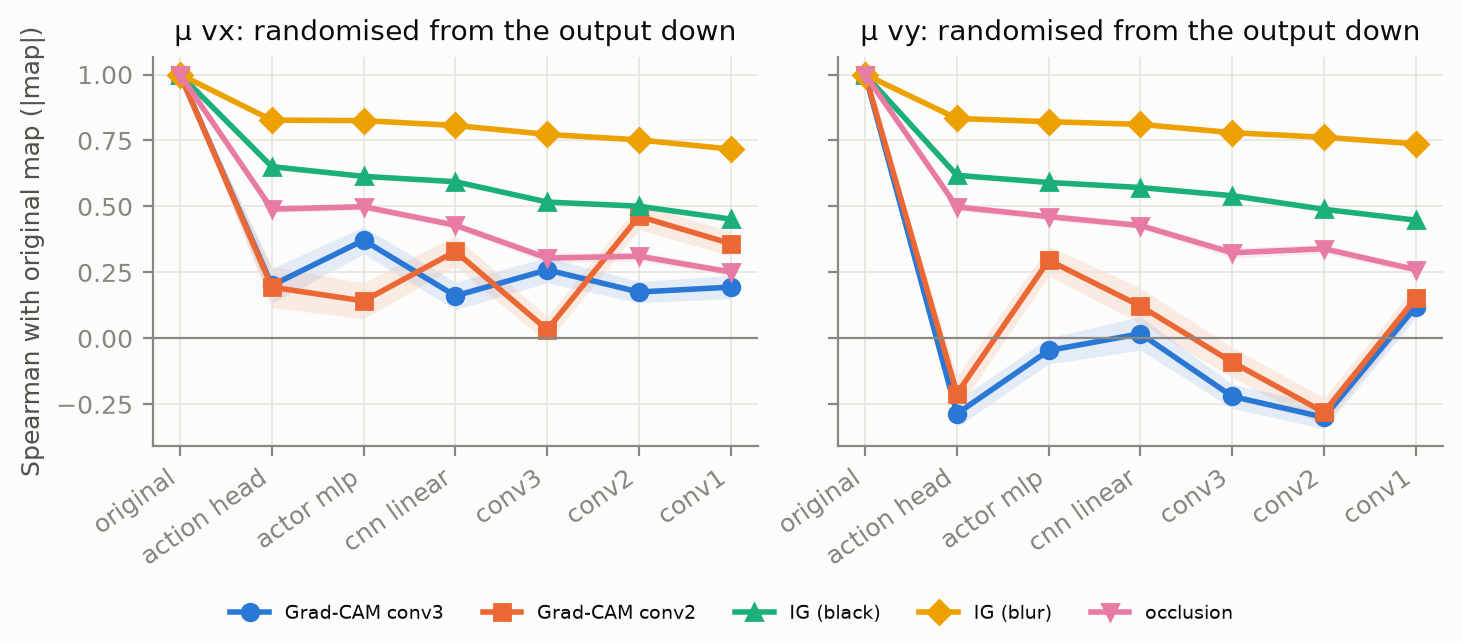

In [15]:
rnd = pd.read_csv(RESULTS / "sanity_randomisation.csv")
display(rnd.groupby(["scalar", "method", "stage"], sort=False)["spearman"].mean().unstack().round(2))
display(Image(FIGURES / "sanity_randomisation.png"))

scalar,vx,vy
order,,
gradcam_conv2,0.205,0.213
gradcam_conv3,0.206,0.217
ig_black,0.092,0.131
ig_blur,0.326,0.364
occlusion,0.365,0.368
random,0.018,0.021


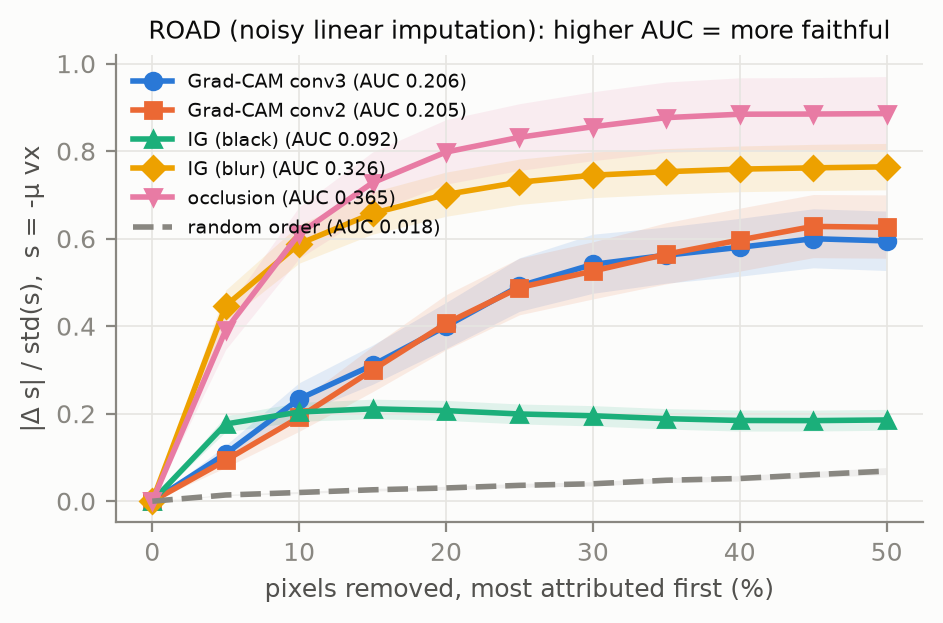

In [16]:
display(pd.read_csv(RESULTS / "sanity_road_auc.csv").pivot(index="order", columns="scalar", values="auc").round(3))
display(Image(FIGURES / "sanity_road_vx.png"))

spearman  top_overlap
scalar a             b                                   
vx     gradcam_conv2 ig_black           0.02         0.12
                     ig_blur            0.02         0.17
                     occlusion          0.17         0.22
       gradcam_conv3 gradcam_conv2      0.45         0.32
                     ig_black           0.00         0.13
                     ig_blur           -0.00         0.20
                     occlusion          0.13         0.21
       ig_black      ig_blur            0.08         0.21
                     occlusion          0.03         0.16
       ig_blur       occlusion          0.17         0.37
vy     gradcam_conv2 ig_black           0.02         0.12
                     ig_blur           -0.00         0.16
                     occlusion          0.10         0.18
       gradcam_conv3 gradcam_conv2      0.52         0.38
                     ig_black          -0.00         0.12
                     ig_blur           -0.01         0.17
                     occlusion          0.11         0.16
       ig_black      ig_blur            0.13         0.22
                     occlusion          0.05         0.17
       ig_blur       occlusion          0.16         0.35

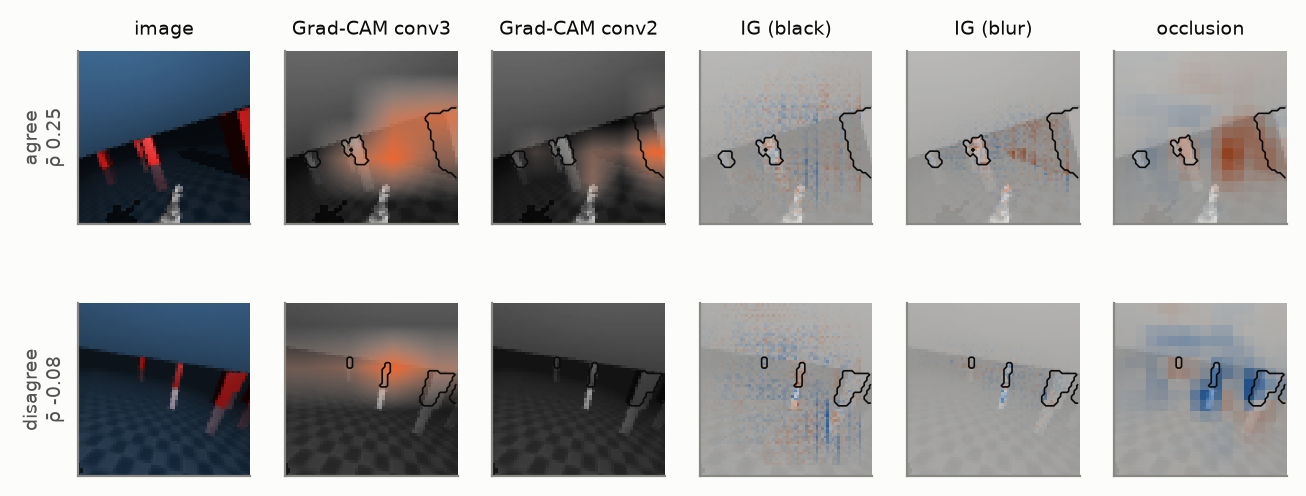

In [17]:
ag = pd.read_csv(RESULTS / "sanity_agreement.csv")
display(ag.groupby(["scalar", "a", "b"])[["spearman", "top_overlap"]].mean().round(2))
display(Image(FIGURES / "sanity_agreement_vx.png"))

In [18]:
pd.read_csv(RESULTS / "sanity_stability_summary.csv")[["scalar", "method", "q_lle", "q_as", "map_change_rel", "shift_map_change_rel", "shift_output_change_std"]]

,scalar,method,q_lle,q_as,map_change_rel,shift_map_change_rel,shift_output_change_std
0,vx,gradcam_conv2,0.254,1.432e-03,0.226,0.919,0.103
1,vx,gradcam_conv3,0.588,3.150e-03,0.120,0.562,0.103
2,vx,ig_black,0.047,4.606e-04,0.060,1.169,0.103
3,vx,ig_blur,0.017,2.532e-04,0.081,1.116,0.103
4,vx,occlusion,0.399,6.489e-03,0.056,0.440,0.103
5,vy,gradcam_conv2,0.148,8.831e-04,0.211,0.784,0.137
6,vy,gradcam_conv3,0.277,1.549e-03,0.176,1.190,0.137
7,vy,ig_black,0.026,2.230e-04,0.057,1.112,0.137
8,vy,ig_blur,0.008,1.188e-04,0.080,1.124,0.137
9,vy,occlusion,0.194,3.126e-03,0.059,0.481,0.137


Randomisation: Spearman between the original map and the map after randomising the network from the output layer down (a method that depends on the learned weights should fall towards 0). ROAD: |Δs|/std(s) after removing the top-p % pixels with noisy linear imputation; a higher AUC means a more faithful ranking (the course's q_ROAD counts unchanged predictions, where lower is better). Stability: q_LLE and q_AS over noise and brightness perturbations that move the output less than 0.1 std; 1-px shifts are reported apart.

**Interpretation:** _(to be written)_

### 6.1 Behaviour test in simulation

In [19]:
b = by_set[by_set.set.isin(["test_id", "baseline_mask_top", "baseline_mask_random"])]
b[["set", "n", "success", "success_lo", "success_hi", "box_hit"]]

,set,n,success,success_lo,success_hi,box_hit
1,baseline_mask_random,51,0.941,0.841,0.980,0.059
2,baseline_mask_top,51,0.745,0.611,0.845,0.255
9,test_id,300,0.937,0.903,0.959,0.047


Every step, the top-10 % Grad-CAM (conv2, braking) pixels are filled with the image's mean colour before the policy sees the image (`baseline_mask_top`); the control hides a region of the same shape at a random offset (`baseline_mask_random`). Same Test-ID seeds, 51 episodes each.

**Interpretation:** _(to be written)_

## 7. Actionable use: before and after

In [20]:
ba = pd.read_csv(RESULTS / "before_after.csv")
ba[["condition", "policy", "detail", "n", "success", "success_lo", "success_hi", "box_hit", "d_success", "d_success_lo", "d_success_hi", "mcnemar_p", "q_rra_gradcam_conv2", "q_rra_occlusion"]]

,condition,policy,detail,n,success,success_lo,success_hi,box_hit,d_success,d_success_lo,d_success_hi,mcnemar_p,q_rra_gradcam_conv2,q_rra_occlusion
0,Test-ID,original,NaN,300,0.937,0.903,0.959,0.047,NaN,NaN,NaN,NaN,0.233,0.242
1,Test-ID,intervention,recolour to red,51,0.980,0.897,0.997,0.020,0.000,0.000,0.000,1.000e+00,NaN,NaN
2,Test-ID,intervention,floor colour normalisation,51,0.980,0.897,0.997,0.020,0.000,0.000,0.000,1.000e+00,NaN,NaN
3,Test-ID,fine-tune,CNN fine-tune with visual randomisation,300,0.840,0.794,0.877,0.067,-0.097,-0.140,-0.057,4.874e-06,0.297,0.184
4,blue boxes,original,NaN,300,0.617,0.561,0.670,0.360,NaN,NaN,NaN,NaN,0.244,0.182
5,blue boxes,intervention,recolour to red,300,0.933,0.899,0.956,0.053,0.317,0.263,0.373,1.355e-25,0.210,0.227
6,blue boxes,fine-tune,CNN fine-tune with visual randomisation,300,0.503,0.447,0.560,0.490,-0.113,-0.180,-0.047,1.240e-03,0.130,0.171
7,floor tint,original,NaN,300,0.707,0.653,0.755,0.083,NaN,NaN,NaN,NaN,0.242,0.188
8,floor tint,intervention,floor colour normalisation,300,0.923,0.888,0.948,0.050,0.217,0.167,0.267,2.442e-16,0.220,0.257
9,floor tint,fine-tune,CNN fine-tune with visual randomisation,300,0.000,0.000,0.013,0.413,-0.707,-0.757,-0.653,3.039e-64,0.008,0.090


Test-time interventions transform the image before the policy, without retraining: recolouring strongly saturated pixels to the training red (applied to the blue-box variant) and bringing the floor pixels' colour to the training floor colour (applied to the floor-tint variant); both are also run on Test-ID to check they do no harm. The fine-tune retrained only the CNN for 1.5M steps with visual randomisation whose ranges exclude the test values. All comparisons are paired on the same seeds.

**Interpretation:** _(to be written)_